In [1]:
#Imort needed packages

import datetime
import pathlib
import yaml

from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Conv2D, MaxPool2D, Dense, Flatten, Dropout

from PIL import Image

2025-08-30 21:09:18.992041: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-08-30 21:09:19.002988: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1756580959.015031 1230631 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1756580959.018825 1230631 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1756580959.028545 1230631 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

# Load constantes

In [2]:
with open("../config.yaml",'r') as config_file:
    config = yaml.safe_load(config_file)
    IMAGE_WIDTH = config["image_width"]
    IMAGE_HEIGHT = config["image_height"]
    IMAGE_DEPTH = config["image_depth"]
    DATA_DIR= pathlib.Path('../data_raw/fgvc-aircraft-2013b/data')
    MODELS_DIR = pathlib.Path(config["models_dir"])
    

# Functions

In [3]:
def build_image_database(path,target):
    """    Build a pandas dataframe with target class and access path to images.

    Parameters:
        - path (Path): Path pattern to read csv file containing images information
        - target(str): The second column to extract from the file

    Return:
        A pandas dataframe,
    -------
    """
    #Load file
    _df= pd.read_csv(path,
            names=["all"],
        )
    #Recover data
    _df["image_id"]=_df["all"].apply(lambda x: x.split(' ')[0])
    _df[target]=_df["all"].apply(lambda x: ' '.join(x.split(' ')[1:]))
    _df[target].unique()

    #Create path
    _df["path"]= _df['image_id'].apply( lambda x: DATA_DIR/"images"/(x+'.jpg')) 
    
    return _df.drop(columns=["all"])

In [4]:
def build_classification_model(df: pd.DataFrame,target: str, images: str):
    """Build a tensorflow model using information from target and images columns in dataframes
    Parameters
    ----------
        - df (pandas.dataFrame): dataframe with target and images columns
        - target (str): column name for target variable
        - images (str): column name for images
    Returns
    ------
    tensorflow model built & compiled
    """
    
    #Compute number of classes for output layer
    nb_classes = df[target].nunique()
    
    # Computer images size for input layer
    size = df[images].iloc[0].shape
    
    # Building the model
    model = Sequential()
    model.add(tf.keras.Input(shape=size)) 
    model.add(Conv2D(filters=32, kernel_size=(5,5), activation='relu'))
    model.add(Conv2D(filters=32, kernel_size=(5,5), activation='relu'))
    model.add(MaxPool2D(pool_size=(2, 2)))
    model.add(Dropout(rate=0.25))
    model.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
    model.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
    model.add(MaxPool2D(pool_size=(2, 2)))
    model.add(Dropout(rate=0.25))
    model.add(Flatten())
    model.add(Dense(256, activation='relu'))
    model.add(Dropout(rate=0.5))
    model.add(Dense(nb_classes , activation='softmax'))

    #Compilation of the model
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy']) #output layer of nb_classes
    
    return model

In [5]:
def show_image(df,row,target):
    """show the image in the ligne row and the associated target column

    Args:
        df (pandas.dataFrame): the dataframe of images
        row (int): the index of the row
        target (string): the column name of the associated label
    Return
    ------
    None
    """

    assert target in df.columns, f"Column {target} not found in dataframe"
    assert 'path' in df.columns, f"Column path doens't not exit in dataframe"
    _img = plt.imread(df.loc[row,'path'])
    print(df.loc[row,target])
    plt.imshow(_img)
    return

In [6]:
def load_resize_image(path,height,width):
    """Load an image and resize it to the target size

    Parameters:
        - path (Path): path to the file to load and resize
        - height (int): the height of the final resized image
        - width(int): the width of the resized image 
    Return
    ------
    numpy.array containing resized image
    """
    return np.array(Image.open(path).resize((width,height)))

In [7]:
def build_x_and_y(df: pd.DataFrame, target: str, images: str):
    """build x tensor and y tensor for model fitting.
    parameters
    ----------
    df(pd.DataFrame): dataframe 
    target(str): name of target column
    images (str): name of resized images column
        
    Returns
    -------
    
    x (numpy.array): tensor of x values
    y (numpy.array): tensor of y values
    """
    
    x= np.array(df[images].to_list())
    y=tf.keras.utils.to_categorical(df[target].astype('category').cat.codes)
    return x,y

In [8]:
def classify_images(images,model,classes_names=None)->int:
    """Classify images through a tensorflow model.
    
    Parameters:
    -----------
    
    images(np.array): set of images to classify
    model (tensorflow.keras.Model): tensorflow/keras model
    
    Returns
    -------
    predicted classes 
    
    """
    
    results = model.predict(images)
    classes = np.argmax(results,axis=1)
    if classes_names is not None:
        classes = np.array(classes_names[classes])
    return classes

In [9]:
def save_model(model ,saving_dir,basename="model",append_time=False):
  """Save tf/Keras model in saving_dir folder

  Parameters
  ----------
  model (tf/Keras model): model to be saved
  basename (str): the basename of the model
  append_time (bool): indicate if the time will be append to the basename
  saving_dir (path): location to save model file
  """
  model.save( f"{saving_dir}/{basename}{'_' + datetime.datetime.now().strftime('%Y-%m-%d_%H-%M-%S') if append_time   else ''}.h5")
  return 

# Read train & test file

In [10]:
manufacturer_train_df = build_image_database(DATA_DIR/"images_manufacturer_train.txt","manufacturer")
manufacturer_test_df = build_image_database(DATA_DIR/"images_manufacturer_test.txt","manufacturer")

In [11]:
# Previous the dataframe 
manufacturer_train_df.head()

,image_id,manufacturer,path
0,1025794,Boeing,../data_raw/fgvc-aircraft-2013b/data/images/10...
1,1340192,Boeing,../data_raw/fgvc-aircraft-2013b/data/images/13...
2,0056978,Boeing,../data_raw/fgvc-aircraft-2013b/data/images/00...
3,0698580,Boeing,../data_raw/fgvc-aircraft-2013b/data/images/06...
4,0450014,Boeing,../data_raw/fgvc-aircraft-2013b/data/images/04...


In [12]:
manufacturer_test_df.head()

,image_id,manufacturer,path
0,1514522,Boeing,../data_raw/fgvc-aircraft-2013b/data/images/15...
1,0747566,Boeing,../data_raw/fgvc-aircraft-2013b/data/images/07...
2,1008575,Boeing,../data_raw/fgvc-aircraft-2013b/data/images/10...
3,0717480,Boeing,../data_raw/fgvc-aircraft-2013b/data/images/07...
4,0991569,Boeing,../data_raw/fgvc-aircraft-2013b/data/images/09...


# View some images

Airbus


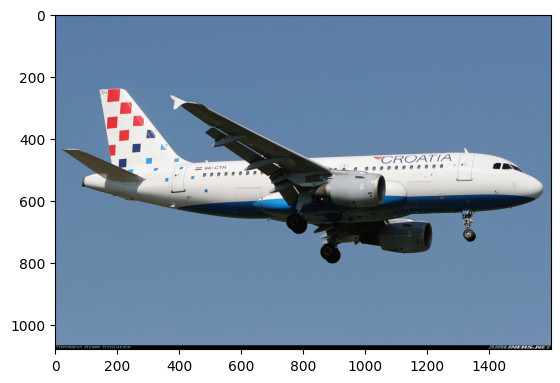

In [13]:
show_image(manufacturer_train_df, np.random.randint(0,manufacturer_train_df.shape[0]), 'manufacturer')

Airbus


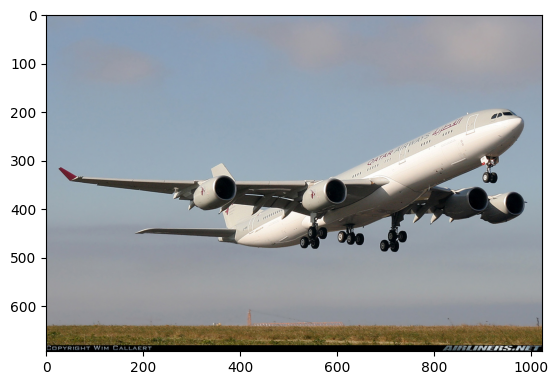

In [14]:
show_image(manufacturer_test_df,np.random.randint(0,manufacturer_test_df.shape[0]),"manufacturer")

# Resize Images

In [15]:
#Resize train images
manufacturer_train_df['resized_image'] = manufacturer_train_df.apply(
        lambda r: load_resize_image(r['path'],IMAGE_HEIGHT,IMAGE_WIDTH),
        axis=1)
#Resize test images
manufacturer_test_df['resized_image'] = manufacturer_test_df.apply(
    lambda r: load_resize_image(r['path'],IMAGE_HEIGHT,IMAGE_WIDTH),
    axis=1)

# Split dataset into x and y

In [16]:
X_train,y_train = build_x_and_y(manufacturer_train_df,'manufacturer','resized_image')
X_test,y_test = build_x_and_y(manufacturer_test_df,'manufacturer','resized_image')

In [17]:
import tensorflow as tf; print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Build & train the model

In [18]:
model = build_classification_model(manufacturer_train_df,"manufacturer","resized_image")

I0000 00:00:1756581072.669533 1230631 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4265 MB memory:  -> device: 0, name: NVIDIA RTX A1000 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


In [20]:
%load_ext tensorboard

!rm -rf ./logs
log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

In [21]:
%%time 
epochs = 5
history = model.fit(X_train,y_train,batch_size = 32,epochs = epochs , validation_data = (X_test,y_test),
                   callbacks=[tensorboard_callback]
                   )

Epoch 1/5


I0000 00:00:1756581120.814945 1232475 service.cc:152] XLA service 0x75fb60011360 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1756581120.814962 1232475 service.cc:160]   StreamExecutor device (0): NVIDIA RTX A1000 6GB Laptop GPU, Compute Capability 8.6
2025-08-30 21:12:00.847631: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1756581121.031200 1232475 cuda_dnn.cc:529] Loaded cuDNN version 91002


  3/105 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.0365 - loss: 276.6611     

I0000 00:00:1756581128.090706 1232475 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


105/105 ━━━━━━━━━━━━━━━━━━━━ 22s 129ms/step - accuracy: 0.1863 - loss: 14.4261 - val_accuracy: 0.2202 - val_loss: 2.9236
Epoch 2/5
105/105 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step - accuracy: 0.2124 - loss: 2.9193 - val_accuracy: 0.2199 - val_loss: 2.8382
Epoch 3/5
105/105 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step - accuracy: 0.2286 - loss: 2.7728 - val_accuracy: 0.2253 - val_loss: 2.7606
Epoch 4/5
105/105 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step - accuracy: 0.2735 - loss: 2.5546 - val_accuracy: 0.2289 - val_loss: 2.7358
Epoch 5/5
105/105 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step - accuracy: 0.3152 - loss: 2.3285 - val_accuracy: 0.2406 - val_loss: 2.6756
CPU times: user 48.7 s, sys: 4.97 s, total: 53.7 s
Wall time: 47.9 s


In [22]:
%tensorboard  --logdir  logs/fit 

Reusing TensorBoard on port 6006 (pid 214885), started 21:11:10 ago. (Use '!kill 214885' to kill it.)

# Predict from the model

In [23]:
classes_names = manufacturer_train_df['manufacturer'].astype('category').cat.categories

In [24]:
classify_images(X_test[10:20],model,classes_names)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


array(['Boeing', 'Boeing', 'Boeing', 'Boeing', 'Boeing', 'Boeing',
       'Boeing', 'Boeing', 'Boeing', 'Boeing'], dtype=object)

# Save the model

In [23]:
save_model(model,MODELS_DIR,basename="manufacturer")

In [ ]:
with open("../models/classes/manufacturer.yaml","w") as classe_file:
    yaml.dump(list(classes_names),classe_file)